# PdM 프로젝트 · 데이터 수집 & 특징 추출 (Colab)
**데이터셋 3종 → 특징(Feature) 테이블(parquet)** 까지를 만드는 노트북입니다.

| 데이터셋 | 용도 | 산출물 |
|---|---|---|
| CWRU Bearing | 결함 유형 분류 (정상/내륜/볼/외륜) | `cwru_features.parquet` |
| NASA IMS Bearing | 열화 추세(Health Index), 20kHz 스트림 | `ims_features.parquet` |
| NASA C-MAPSS | RUL 예측 (센서 다변량) | `cmapss_fd001.parquet` |

**순서**: 0 환경설정 → 1 데이터 준비 → 2 특징 추출 함수 → 3 CWRU → 4 IMS → 5 C-MAPSS → 6 저장

## 0. 환경 설정

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
BASE = Path('/content/drive/MyDrive/pdm_project')
for sub in ['cwru', 'ims', 'cmapss', 'features']:
    (BASE / sub).mkdir(parents=True, exist_ok=True)
print(BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/pdm_project


## 1. 데이터 준비
- **CWRU**
- **IMS**
- **C-MAPSS**

In [ ]:
# IMS는 로컬 디스크로 복사 (Drive에서 작은 파일 984개를 읽으면 느림)
!mkdir -p /content/ims_local
!cp -r "/content/drive/MyDrive/pdm_project/ims/2nd_test" /content/ims_local/

cmapss_root = BASE / 'cmapss'
ims_root    = Path('/content/ims_local')      # 이 아래에 2nd_test 폴더가 생김

def find_file(root, name):
    hits = list(Path(root).rglob(name))
    if not hits: raise FileNotFoundError(name)
    return hits[0]

def find_dir_with_most_files(root, dirname):
    cands = [p for p in Path(root).rglob(dirname) if p.is_dir()]
    cands = [p for p in cands if any(q.is_file() for q in p.iterdir())]
    return max(cands, key=lambda p: sum(q.is_file() for q in p.iterdir()))

print(find_file(cmapss_root, 'train_FD001.txt'))
print(find_dir_with_most_files(ims_root, '2nd_test'))

/content/drive/MyDrive/pdm_project/cmapss/train_FD001.txt
/content/ims_local/2nd_test


## 2. 공통 특징 추출 함수
- **시간 영역**: RMS, Peak, P2P, Kurtosis, Skewness, Crest Factor, Shape/Impulse Factor
- **주파수 영역**: Hanning 윈도우 FFT → 스펙트럼 엔트로피, 중심주파수, 1X/2X/3X 및 BPFO/BPFI/BSF 피크
- **엔벨로프 분석**: 고주파 공진대역 대역통과 → Hilbert 포락선 → FFT. 베어링 결함은 원신호 FFT보다 엔벨로프 스펙트럼에서 훨씬 뚜렷하게 보입니다.

In [ ]:
import numpy as np, pandas as pd
from scipy import signal, stats
from scipy.fft import rfft, rfftfreq

# 베어링 결함 추출 함수
def bearing_freqs(shaft_hz, n, d, D, theta_deg=0.0):
    """결함 주파수(Hz). n=볼/롤러 수, d=볼 지름, D=피치 지름."""
    r = d / D * np.cos(np.radians(theta_deg))
    return {
        'BPFO': n / 2 * shaft_hz * (1 - r),
        'BPFI': n / 2 * shaft_hz * (1 + r),
        'BSF' : D / (2 * d) * shaft_hz * (1 - r**2),
        'FTF' : shaft_hz / 2 * (1 - r),
    }

# 시간 영역 피처 추출 함수
def time_features(x):
    rms = np.sqrt(np.mean(x**2)); peak = np.max(np.abs(x)); mabs = np.mean(np.abs(x))
    return {
        'mean': x.mean(), 'std': x.std(), 'rms': rms, 'peak': peak,
        'p2p': x.max() - x.min(),
        'kurtosis': stats.kurtosis(x), 'skew': stats.skew(x),
        'crest': peak / rms, 'shape': rms / mabs, 'impulse': peak / mabs,
    }
# 주파수 추출 (Hanning 윈도우 적용한 fft를 통해서 주파수 피크 추출)
def amp_spectrum(x, fs):
    w = signal.windows.hann(len(x))                  # Hanning 윈도우
    X = np.abs(rfft((x - x.mean()) * w)) * 2 / w.sum()
    return rfftfreq(len(x), 1 / fs), X

def band_peak(f, X, f0, tol_hz):
    m = (f >= f0 - tol_hz) & (f <= f0 + tol_hz)
    return float(X[m].max()) if m.any() else 0.0

def freq_features(x, fs, shaft_hz, fault, prefix='', n_harm=2, tol_ratio=0.03):
    f, X = amp_spectrum(x, fs)
    df = f[1] - f[0]
    P = X**2; Pn = P / (P.sum() + 1e-18)
    out = {
        f'{prefix}spec_entropy' : float(-(Pn * np.log(Pn + 1e-18)).sum()),
        f'{prefix}spec_centroid': float((f * Pn).sum()),
        f'{prefix}spec_peak_hz' : float(f[np.argmax(X)]),
    }
    targets = {'1X': shaft_hz, '2X': 2 * shaft_hz, '3X': 3 * shaft_hz}
    for name in ['BPFO', 'BPFI', 'BSF']:
        for h in range(1, n_harm + 1):
            targets[f'{name}_h{h}'] = fault[name] * h
    for k, f0 in targets.items():
        out[f'{prefix}{k}'] = band_peak(f, X, f0, max(f0 * tol_ratio, 2 * df))
    return out

# 엔벨로프 분석 피처(힐베르트 변환을 거쳐서 스펙트럼을 구한다, 베어링 결함 진단용)
def envelope_features(x, fs, fault, band=(2000, 5000), prefix='env_', n_harm=2, tol_ratio=0.03):
    nyq = fs / 2
    hi = min(band[1], nyq * 0.95)
    sos = signal.butter(4, [band[0] / nyq, hi / nyq], btype='band', output='sos')
    env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, x)))
    f, X = amp_spectrum(env, fs)
    df = f[1] - f[0]
    out = {}
    for name in ['BPFO', 'BPFI', 'BSF']:
        for h in range(1, n_harm + 1):
            f0 = fault[name] * h
            out[f'{prefix}{name}_h{h}'] = band_peak(f, X, f0, max(f0 * tol_ratio, 2 * df))
    return out

def extract_all(x, fs, shaft_hz, fault, env_band):
    x = np.asarray(x, dtype=float)
    feats = time_features(x)
    feats.update(freq_features(x, fs, shaft_hz, fault))
    feats.update(envelope_features(x, fs, fault, band=env_band))
    return feats

# 슬라이딩 윈도우(시계열 데이터를 일정한 크기 간격으로)
def sliding_windows(x, size, hop):
    for i in range(0, len(x) - size + 1, hop):
        yield i, x[i:i + size]

## 3. CWRU: 결함 유형 분류용 특징 추출
- 12kHz Drive End, 베어링 SKF 6205-2RS (볼 9개, d=0.3126in, D=1.537in)
- 2048 샘플(≈0.17초) 윈도우, 50% 오버랩

In [ ]:
from scipy.io import loadmat

CWRU_FS = 12_000
# 파일번호: (결함유형, 결함크기[inch], 부하[HP])  ※ 12k Drive End 기준
CWRU_META = {
    97:  ('normal', 0.000, 0),
    105: ('inner', 0.007, 0), 118: ('ball', 0.007, 0), 130: ('outer', 0.007, 0),
    209: ('inner', 0.021, 0), 222: ('ball', 0.021, 0), 234: ('outer', 0.021, 0),
    # 3HP(약 1730rpm)
    100: ('normal', 0.000, 3),
    108: ('inner', 0.007, 3), 121: ('ball', 0.007, 3), 133: ('outer', 0.007, 3),
    212: ('inner', 0.021, 3), 225: ('ball', 0.021, 3), 237: ('outer', 0.021, 3),
}

def load_cwru(path):
    m = loadmat(path)
    key = [k for k in m if k.endswith('_DE_time')][0]
    rpm_key = [k for k in m if k.endswith('RPM')]
    rpm = float(np.ravel(m[rpm_key[0]])[0]) if rpm_key else 1797.0
    return np.ravel(m[key]).astype(float), rpm

rows = []
for num, (label, size, load) in CWRU_META.items():
    path = BASE / 'cwru' / f'{num}.mat'
    if not path.exists():
        print(f'건너뜀(파일 없음): {num}.mat'); continue
    x, rpm = load_cwru(path)
    print(f'{num:>3}  {label:<6} size={size}  load={load}HP  rpm={rpm:.0f}  n={len(x)}')
    shaft = rpm / 60                       # 파일마다 실제 rpm으로 결함 주파수 계산
    fault = bearing_freqs(shaft, n=9, d=0.3126, D=1.537, theta_deg=0)  # 베어링 결함 계산
    for pos, seg in sliding_windows(x, 2048, 1024):  # 일정하게 잘라주기
        feats = extract_all(seg, CWRU_FS, shaft, fault, env_band=(2000, 5000))
        feats.update(file_id=num, label=label, severity=size, load_hp=load, rpm=rpm, win_idx=pos // 1024)
        rows.append(feats)

df_cwru = pd.DataFrame(rows)
print(df_cwru.shape)
print(df_cwru.groupby(['load_hp','label','severity']).size())
df_cwru.head()

 97  normal size=0.0  load=0HP  rpm=1796  n=243938
105  inner  size=0.007  load=0HP  rpm=1797  n=121265
118  ball   size=0.007  load=0HP  rpm=1796  n=122571
130  outer  size=0.007  load=0HP  rpm=1796  n=121991
209  inner  size=0.021  load=0HP  rpm=1797  n=122136
222  ball   size=0.021  load=0HP  rpm=1796  n=121991
234  outer  size=0.021  load=0HP  rpm=1796  n=122426
100  normal size=0.0  load=3HP  rpm=1725  n=485643
108  inner  size=0.007  load=3HP  rpm=1721  n=122917
121  ball   size=0.007  load=3HP  rpm=1722  n=121556
133  outer  size=0.007  load=3HP  rpm=1725  n=122571
건너뜀(파일 없음): 212.mat
건너뜀(파일 없음): 225.mat
건너뜀(파일 없음): 237.mat
(1771, 34)
load_hp  label   severity
0        ball    0.007       118
                 0.021       118
         inner   0.007       117
                 0.021       118
         normal  0.000       237
         outer   0.007       118
                 0.021       118
3        ball    0.007       117
         inner   0.007       119
         normal  0.000     

,mean,std,rms,peak,p2p,kurtosis,skew,crest,shape,impulse,...,env_BPFI_h1,env_BPFI_h2,env_BSF_h1,env_BSF_h2,file_id,label,severity,load_hp,rpm,win_idx
0,0.012005,0.072266,0.073256,0.272869,0.490663,-0.045824,-0.137322,3.724845,1.247561,4.646972,...,0.000571,0.000538,0.000703,0.000572,97,normal,0.0,0,1796.0,0
1,0.013116,0.073344,0.074507,0.272869,0.485239,-0.116338,-0.010099,3.662321,1.253476,4.590630,...,0.000554,0.000872,0.001249,0.000319,97,normal,0.0,0,1796.0,1
2,0.012790,0.077993,0.079035,0.226765,0.449775,-0.184580,-0.062348,2.869171,1.247298,3.578710,...,0.000422,0.000304,0.000795,0.000279,97,normal,0.0,0,1796.0,2
3,0.012148,0.076964,0.077916,0.226765,0.449775,-0.150657,-0.103819,2.910361,1.249439,3.636318,...,0.000390,0.000304,0.001075,0.000435,97,normal,0.0,0,1796.0,3
4,0.011959,0.073370,0.074338,0.219255,0.421403,-0.221760,0.025960,2.949440,1.250528,3.688358,...,0.000329,0.000428,0.000861,0.000245,97,normal,0.0,0,1796.0,4


### 3-1. 베이스라인 분류 (Random Forest / XGBoost)
같은 파일에서 윈도우를 랜덤 분할하면 인접 윈도우가 겹쳐 **점수가 부풀려집니다(데이터 누수)**.
여기서는 파일 내 **시간순 분할(앞 70% 학습 / 뒤 30% 테스트, 사이에 간격)** 을 씁니다.
부하(0~3HP) 파일을 더 받으면 **'부하 하나를 통째로 테스트'(leave-one-load-out)** 로 확장하는 것이 가장 정직한 평가입니다.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

# 데이터 분할하기
def chrono_split(df, train_ratio=0.7, gap=2):
    tr, te = [], []
    for _, g in df.groupby('file_id'):
        g = g.sort_values('win_idx'); n = len(g); cut = int(n * train_ratio)
        tr.append(g.iloc[:cut]); te.append(g.iloc[cut + gap:])
    return pd.concat(tr), pd.concat(te)

META = ('file_id', 'label', 'severity', 'load_hp', 'rpm', 'win_idx')
feat_cols = [c for c in df_cwru.columns if c not in META]
df0 = df_cwru[df_cwru.load_hp == 0]
train, test = chrono_split(df0)
le = LabelEncoder().fit(df_cwru.label)

rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=0, n_jobs=-1)
rf.fit(train[feat_cols], le.transform(train.label))
pred = rf.predict(test[feat_cols])
print('== Random Forest ==')
print(classification_report(le.transform(test.label), pred, target_names=le.classes_))
print(confusion_matrix(le.transform(test.label), pred))

xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, eval_metric='mlogloss')
xgb.fit(train[feat_cols], le.transform(train.label))
print('== XGBoost ==')
print(classification_report(le.transform(test.label), xgb.predict(test[feat_cols]), target_names=le.classes_))

imp = pd.Series(rf.feature_importances_, index=feat_cols).sort_values(ascending=False)
imp.head(15)

== Random Forest ==
              precision    recall  f1-score   support

        ball       1.00      1.00      1.00        68
       inner       1.00      1.00      1.00        68
      normal       1.00      1.00      1.00        70
       outer       1.00      1.00      1.00        68

    accuracy                           1.00       274
   macro avg       1.00      1.00      1.00       274
weighted avg       1.00      1.00      1.00       274

[[68  0  0  0]
 [ 0 68  0  0]
 [ 0  0 70  0]
 [ 0  0  0 68]]
== XGBoost ==
              precision    recall  f1-score   support

        ball       1.00      1.00      1.00        68
       inner       1.00      1.00      1.00        68
      normal       1.00      1.00      1.00        70
       outer       1.00      1.00      1.00        68

    accuracy                           1.00       274
   macro avg       1.00      1.00      1.00       274
weighted avg       1.00      1.00      1.00       274



,0
env_BPFO_h1,0.099501
env_BPFI_h1,0.098585
env_BPFI_h2,0.092843
std,0.089986
rms,0.088222
env_BPFO_h2,0.087617
shape,0.085499
p2p,0.052830
spec_centroid,0.049407
peak,0.045530


### 3-2. 부하가 다른 데이터로 일반화 테스트 (0HP 학습 → 3HP 테스트)
3HP 파일이 있으면 가장 정직한 평가입니다. 같은 파일의 앞/뒤를 나누는 것보다 훨씬 어렵고, 실제 현장 상황(부하·속도 변화)에 가깝습니다.

In [ ]:
df3 = df_cwru[df_cwru.load_hp == 3]
if len(df3) == 0:
    print('3HP 파일이 없습니다. CWRU_META의 3HP 번호 파일을 cwru/ 폴더에 넣고 3번 셀부터 다시 실행하세요.')
else: # 0HP 부하로 학습한 모델을 3HP 부하 데이터에 적용
    rf2 = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=0, n_jobs=-1)
    rf2.fit(df0[feat_cols], df0.label)
    p = rf2.predict(df3[feat_cols])
    print(classification_report(df3.label, p))
    print(pd.crosstab(df3.label, p, rownames=['true'], colnames=['pred']))

              precision    recall  f1-score   support

        ball       1.00      1.00      1.00       117
       inner       1.00      1.00      1.00       119
      normal       1.00      1.00      1.00       473
       outer       1.00      1.00      1.00       118

    accuracy                           1.00       827
   macro avg       1.00      1.00      1.00       827
weighted avg       1.00      1.00      1.00       827

pred    ball  inner  normal  outer
true                              
ball     117      0       0      0
inner      0    119       0      0
normal     0      0     473      0
outer      0      0       0    118


## 4. IMS: 런투페일 열화 추세 특징
IMS : 고장이 발생할 때까지 수집된 진동 데이터
- 20,480Hz, 파일 1개 = 1초(20,480 샘플), 10분 간격, 2000rpm
- **2nd_test**: 채널 4개(베어링 1~4, 각 1채널), **베어링 1에서 외륜 결함으로 고장**
- Rexnord ZA-2115: 롤러 16개, d=0.331in, D=2.815in, 접촉각 15.17°

In [ ]:
import os
from datetime import datetime

IMS_FS = 20_480
IMS_SHAFT = 2000 / 60
IMS_FAULT = bearing_freqs(IMS_SHAFT, n=16, d=0.331, D=2.815, theta_deg=15.17)
print({k: round(v, 1) for k, v in IMS_FAULT.items()})    # BPFO≈236, BPFI≈297 Hz

ims_dir = find_dir_with_most_files(ims_root, '2nd_test')
files = sorted(p for p in ims_dir.iterdir() if p.is_file())
print(ims_dir, len(files))

import re
def ims_to_time(name):
    # '2004.02.12.10.32.39' 또는 '2004_02_12_10_32.39' 처럼 구분자가 달라도 숫자 6개만 뽑아 파싱
    y, mo, d, h, mi, sec = map(int, re.findall(r'\d+', name)[:6])
    return datetime(y, mo, d, h, mi, sec)

CH = 0      # 베어링 1 (고장 베어링)
t0 = ims_to_time(files[0].name)
rows = []
for i, p in enumerate(files):
    arr = pd.read_csv(p, sep='\t', header=None).values
    x = arr[:, CH]
    feats = extract_all(x, IMS_FS, IMS_SHAFT, IMS_FAULT, env_band=(2000, 9000))
    feats['elapsed_h'] = (ims_to_time(p.name) - t0).total_seconds() / 3600  # elapsed_h: 경과시간(사용시간)
    feats['file_idx'] = i
    rows.append(feats)

df_ims = pd.DataFrame(rows)
df_ims['RUL_h'] = df_ims.elapsed_h.max() - df_ims.elapsed_h      # RUL_h : 실제 고장 시점 기준 남은 시간 (남은 수명)
df_ims.tail()

{'BPFO': np.float64(236.4), 'BPFI': np.float64(296.9), 'BSF': np.float64(139.9), 'FTF': np.float64(14.8)}
/content/ims_local/2nd_test 984


,mean,std,rms,peak,p2p,kurtosis,skew,crest,shape,impulse,...,BSF_h2,env_BPFO_h1,env_BPFO_h2,env_BPFI_h1,env_BPFI_h2,env_BSF_h1,env_BSF_h2,elapsed_h,file_idx,RUL_h
979,-0.002752,0.724996,0.725001,5.000,9.998,12.577705,-0.510556,6.896538,1.599323,11.029794,...,0.012860,0.364429,0.282936,0.029278,0.018011,0.015610,0.032496,163.166667,979,0.666667
980,-0.004487,0.461990,0.462012,2.881,5.569,3.759972,-0.325368,6.235773,1.368621,8.534412,...,0.009226,0.164317,0.155197,0.038458,0.010839,0.006381,0.013999,163.333333,980,0.500000
981,-0.001703,0.483832,0.483835,3.696,7.197,4.891755,-0.377095,7.638962,1.378077,10.527081,...,0.011824,0.163478,0.170407,0.013694,0.012318,0.007870,0.014698,163.500000,981,0.333333
982,0.001857,0.000987,0.002103,0.005,0.005,3.637513,0.579698,2.377543,1.132578,2.692753,...,0.000055,0.000399,0.000056,0.000105,0.000053,0.000052,0.000035,163.666667,982,0.166667
983,-0.001162,0.001000,0.001533,0.005,0.007,-1.609774,0.317032,3.262149,1.311812,4.279326,...,0.000031,0.000318,0.000066,0.000104,0.000032,0.000018,0.000025,163.833333,983,0.000000


# 사용시간(elapsed_h)이 증가할 수록 RMS, Kurtosis, Envelope BPFO 값들이 큰 폭의 변화를 보이다가 고장나는 순간 값이 0으로 마무리된다.

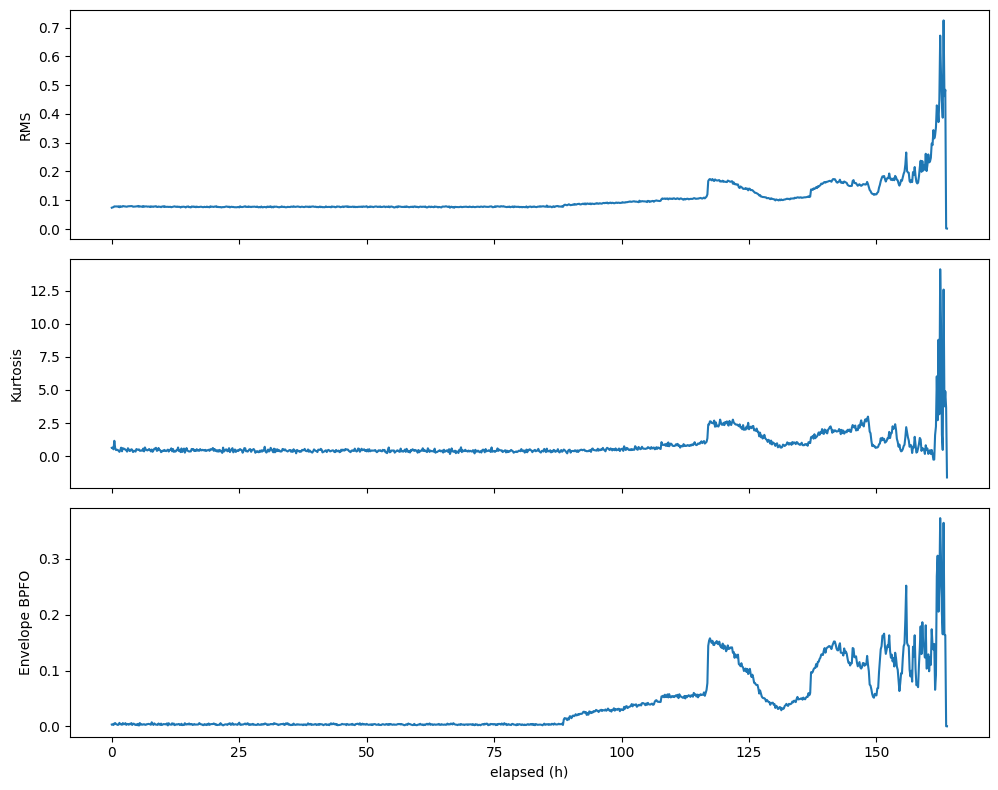

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
t = df_ims['elapsed_h']
ax[0].plot(t, df_ims['rms']);          ax[0].set_ylabel('RMS')  # 진동 에너지 크기 (떨림이 어느정도 발생하는 지) (전체적인 상태 확인)
ax[1].plot(t, df_ims['kurtosis']);     ax[1].set_ylabel('Kurtosis') # 첨도 :  베어링 균열로 인한 볼 회전 충격파 확인용 (초기 고장 확인)
ax[2].plot(t, df_ims['env_BPFO_h1']);  ax[2].set_ylabel('Envelope BPFO'); ax[2].set_xlabel('elapsed (h)') # 베어링 외륜 결함 확인 (결함 부위 특)
plt.tight_layout(); plt.show()

### 4-1. 간이 Health Index (0~100)
초기 구간(정상으로 가정)의 특징 분포 대비 **마할라노비스 거리**(정상으로 부터 얼마나 떨어져 있는 지 측정하는 지표)를 구해 0~100으로 스케일링합니다.
대시보드의 건전성 지수와 같은 개념이며, 나중에 Autoencoder 재구성 오차로 대체할 수 있습니다.

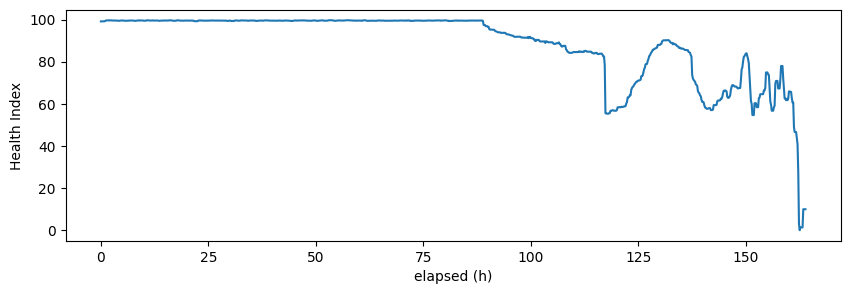

In [ ]:
from sklearn.preprocessing import StandardScaler
hi_cols = ['rms', 'kurtosis', 'crest', 'env_BPFO_h1', 'env_BPFO_h2', 'BPFO_h1']
base = df_ims[hi_cols].iloc[: int(len(df_ims) * 0.1)]          # 앞 10% = 정상 기준
sc = StandardScaler().fit(base)
Z = sc.transform(df_ims[hi_cols])
cov_inv = np.linalg.pinv(np.cov(sc.transform(base).T) + 1e-6 * np.eye(len(hi_cols)))
d = np.sqrt(np.einsum('ij,jk,ik->i', Z, cov_inv, Z))
d_s = pd.Series(d).rolling(5, min_periods=1).median()
df_ims['health_index'] = 100 * (1 - np.clip(d_s / d_s.max(), 0, 1))

plt.figure(figsize=(10, 3)); plt.plot(df_ims.elapsed_h, df_ims.health_index)
plt.ylabel('Health Index'); plt.xlabel('elapsed (h)'); plt.show()

## 5. C-MAPSS (FD001): RUL 학습용 테이블
C-MAPSS는 **진동 파형이 아니라 사이클 단위 다변량 센서(21개)** 입니다. 그래서 FFT 대신 **롤링 통계**로 특징을 만듭니다.
RUL은 초기에 열화가 없으므로 **상한 125로 클리핑(piecewise-linear RUL)** 하는 것이 표준입니다.

In [ ]:
cols = ['unit', 'cycle'] + [f'op{i}' for i in range(1, 4)] + [f's{i}' for i in range(1, 22)]
train_fd1 = pd.read_csv(find_file(cmapss_root, 'train_FD001.txt'), sep=r'\s+', header=None, names=cols)

train_fd1['RUL'] = train_fd1.groupby('unit').cycle.transform('max') - train_fd1.cycle
train_fd1['RUL_clip'] = train_fd1.RUL.clip(upper=125)

sensor_cols = [c for c in cols if c.startswith('s')]
sensor_cols = [c for c in sensor_cols if train_fd1[c].std() > 1e-6]      # 상수 센서 제거
print('사용 센서:', sensor_cols)

g = train_fd1.groupby('unit')
for c in sensor_cols:
    train_fd1[f'{c}_rm30'] = g[c].transform(lambda s: s.rolling(30, min_periods=1).mean())
    train_fd1[f'{c}_rs30'] = g[c].transform(lambda s: s.rolling(30, min_periods=1).std().fillna(0))
train_fd1.head()

사용 센서: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s14_rm30,s14_rs30,s15_rm30,s15_rs30,s17_rm30,s17_rs30,s20_rm30,s20_rs30,s21_rm30,s21_rs30
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.620000,0.000000,8.419500,0.000000,392.000000,0.000000,39.060000,0.000000,23.419000,0.000000
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8135.055000,5.041671,8.425650,0.008697,392.000000,0.000000,39.030000,0.042426,23.421300,0.003253
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8134.446667,3.717450,8.423033,0.007640,391.333333,1.154701,39.003333,0.055076,23.395600,0.044573
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8134.292500,3.050906,8.409325,0.028117,391.500000,1.000000,38.972500,0.076322,23.390175,0.037977
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8134.194000,2.651326,8.413340,0.025953,391.800000,1.095445,38.958000,0.073621,23.393020,0.033498


## 6. 저장
Drive의 `features/` 폴더에 parquet로 저장합니다. 이 파일을 읽어 **FastAPI → Kafka → TimescaleDB** 로 리플레이해서 실제 데이터셋으로 스트리밍 테스트 시 사용

In [ ]:
df_cwru.to_parquet(BASE / 'features' / 'cwru_features.parquet', index=False)
df_ims.to_parquet(BASE / 'features' / 'ims_features.parquet', index=False)
train_fd1.to_parquet(BASE / 'features' / 'cmapss_fd001.parquet', index=False)
print(sorted(p.name for p in (BASE / 'features').iterdir()))

['cmapss_fd001.parquet', 'cwru_features.parquet', 'ims_features.parquet']


In [ ]:
for name in ['cwru_features', 'ims_features', 'cmapss_fd001']:
    d = pd.read_parquet(BASE / 'features' / f'{name}.parquet')
    print(name, d.shape, '| NaN:', int(d.isna().sum().sum()))

cwru_features (1771, 34) | NaN: 0
ims_features (984, 32) | NaN: 0
cmapss_fd001 (20631, 58) | NaN: 0


In [ ]:
print(df_cwru.groupby(['file_id', 'label', 'severity', 'load_hp']).size())

file_id  label   severity  load_hp
97       normal  0.000     0          237
100      normal  0.000     3          473
105      inner   0.007     0          117
108      inner   0.007     3          119
118      ball    0.007     0          118
121      ball    0.007     3          117
130      outer   0.007     0          118
133      outer   0.007     3          118
209      inner   0.021     0          118
222      ball    0.021     0          118
234      outer   0.021     0          118
dtype: int64


In [ ]:
# (1) 결함 크기 일반화: 0.021로만 학습 → 0.007 테스트 (두 부하 모두)
tr = df_cwru[(df_cwru.severity.isin([0.0, 0.021])) & (df_cwru.load_hp == 0)]
te = df_cwru[df_cwru.severity == 0.007]
m = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=0, n_jobs=-1)
m.fit(tr[feat_cols], tr.label)
p = m.predict(te[feat_cols])
print(classification_report(te.label, p))
print(pd.crosstab(te.label, p, rownames=['true'], colnames=['pred']))

# (2) 엔벨로프 특징만 사용 (어떤 특징이 일을 하는지 확인)
env_cols = [c for c in feat_cols if c.startswith('env_')]
m2 = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=0, n_jobs=-1)
m2.fit(df0[env_cols], df0.label)
d3 = df_cwru[df_cwru.load_hp == 3]
print('env-only, 0HP->3HP acc:', (m2.predict(d3[env_cols]) == d3.label).mean())

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

        ball       0.50      1.00      0.67       235
       inner       0.00      0.00      0.00       236
       outer       0.00      0.00      0.00       236

    accuracy                           0.33       707
   macro avg       0.17      0.33      0.22       707
weighted avg       0.17      0.33      0.22       707

pred   ball  inner
true              
ball    235      0
inner   236      0
outer     0    236
env-only, 0HP->3HP acc: 1.0
